# Chapter 10: Language Translation with Seq2seq and Encoder-Decoder Models!!!

In [1]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt

In [2]:
english_words = ['lets', 'to', 'go', '.']
spanish_words = ['ir', 'vamos', 'y', '.']
english_word_count = len(english_words)
spanish_word_count = len(spanish_words)
data = [
    ['lets go', 'vamos .'],
    ['to go', 'ir .'],
]

X_raw = []
y_raw = []

for one_data in data:
    X_one_data = []
    words = one_data[0].split()

    for word in words:
        X_one_data.append(english_words.index(word))
        
    X_raw.append(X_one_data)
    
    y_one_data = []
    words = one_data[1].split()
    
    for word in words:
        y_one_data.append(spanish_words.index(word))
        
    y_raw.append(y_one_data)
    
X_tensor = torch.tensor(X_raw).int()
y_tensor = torch.tensor(y_raw).int()

tensor_data = TensorDataset(X_tensor, y_tensor)
data_loader = DataLoader(tensor_data, shuffle=True)

In [3]:
hidden_size = 2
num_layers = 2
embedding_dim = 2
spanish_dot = torch.tensor(3)

class EncDecNet(nn.Module):
    def __init__(self):
        super().__init__()
        
        self.enc_embed = nn.Embedding(num_embeddings=english_word_count, embedding_dim=embedding_dim)
        self.enc_lstm = nn.LSTM(input_size=embedding_dim, hidden_size=hidden_size, num_layers=num_layers)
        self.dec_embed = nn.Embedding(num_embeddings=spanish_word_count, embedding_dim=embedding_dim)
        self.dec_lstm = nn.LSTM(input_size=embedding_dim, hidden_size=hidden_size, num_layers=num_layers)
        self.dec_linear = nn.Linear(hidden_size, spanish_word_count)
        
    def forward(self, x_english, x_spanish, teacher_forcing=True):
        english_words_embedding = self.enc_embed(x_english[0])
        _, english_words_states = self.enc_lstm(english_words_embedding)

        context_vector = english_words_states

        if teacher_forcing:
            spanish_words_embedding = self.dec_embed(x_spanish[0])
            spanish_pred_words, spanish_words_states = self.dec_lstm(spanish_words_embedding, context_vector)

            return self.dec_linear(spanish_pred_words)
        else:
            max_steps = 10
            current_step = 0
            new_spanish_word = spanish_dot
            h_and_c = context_vector
            spanish_pred_words = torch.tensor([[]])
            
            while True:
                current_step += 1
                
                spanish_word_embedding = self.dec_embed(new_spanish_word)
                spanish_pred_word, h_and_c = self.dec_lstm(spanish_word_embedding.unsqueeze(dim=0), h_and_c)
                new_spanish_word = torch.argmax(self.dec_linear(spanish_pred_word), dim=1).squeeze()
                spanish_pred_words = torch.cat((spanish_pred_words, torch.tensor([[new_spanish_word]])), dim=1)

                if current_step == max_steps or new_spanish_word == spanish_dot:
                    break
                
            return spanish_pred_words.int()

In [4]:
enc_dec_net = EncDecNet()
optimizer = torch.optim.Adam(enc_dec_net.parameters())
loss_func = torch.nn.CrossEntropyLoss()
losses = []

enc_dec_net.train()

for epoch in range(2000):
    for X, y in data_loader:
        flipped_y = torch.flip(y, dims=(1,))
        y_pred = enc_dec_net(X, flipped_y)

        y_pred_target = y_pred
        y_target = y[0].long()

        loss = loss_func(y_pred_target, y_target)
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        losses.append(loss.detach().item())

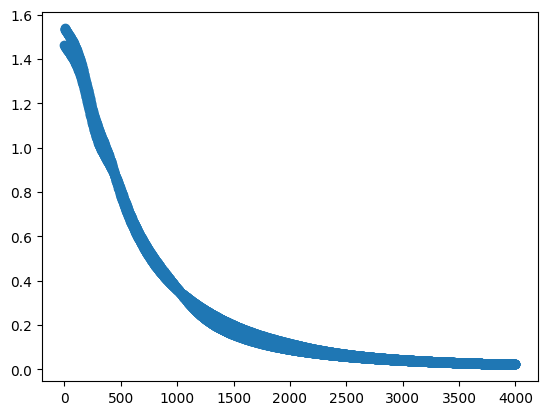

In [5]:
plt.scatter(range(len(losses)), losses)
plt.show()

In [6]:
enc_dec_net.eval()

for X, y in data_loader:
    y_pred = enc_dec_net(X, _, teacher_forcing=False)

    print(y_pred)
    print(y)
    print('---------------')

tensor([[1, 3]], dtype=torch.int32)
tensor([[1, 3]], dtype=torch.int32)
---------------
tensor([[0, 3]], dtype=torch.int32)
tensor([[0, 3]], dtype=torch.int32)
---------------
